In [1]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)

from DTT_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Initialize parameters

In [2]:
plot=1

In [3]:
os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Calibration')

f = 1500
coeff = 0.65 #diffraction limit coeff

lda = 500e-9
d0 = coeff*lda
delta_y = 300e-9


Lambda = np.linspace(375e-9, 1040e-9, 50)
D0 = coeff*Lambda
Delta_y = np.linspace(1e-12, 700e-9, 100)



## Comparer Airy et Gaussien

On varie Delta_y

<>:11: SyntaxWarning: invalid escape sequence '\d'
<>:12: SyntaxWarning: invalid escape sequence '\g'
<>:11: SyntaxWarning: invalid escape sequence '\d'
<>:12: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nberr\AppData\Local\Temp\ipykernel_9900\310726113.py:11: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel('$\delta_y$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_9900\310726113.py:12: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')


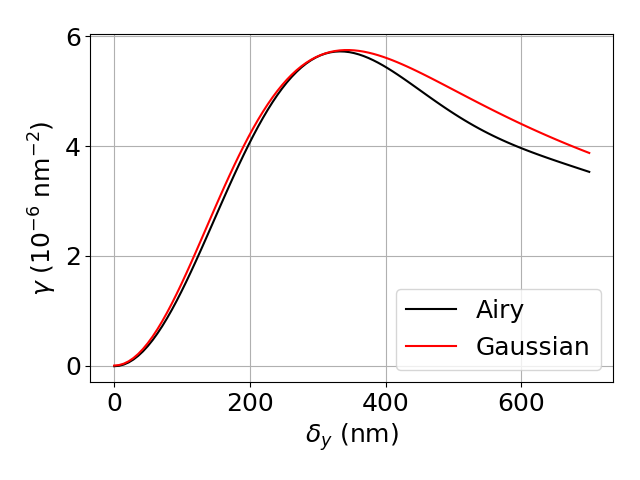

In [4]:
Res_Airy = Response_function(d0, Delta_y, beam='Airy')
Res_Gaussian = Response_function(d0, Delta_y, beam='Gaussian')


fig = plt.figure()

plt.plot(Delta_y*1e9, Res_Airy*1e-12, color='black', label='Airy')
plt.plot(Delta_y*1e9, Res_Gaussian*1e-12, color='red', label="Gaussian")
#plt.plot(Delta_y*1e9, -Res_DL*1e18, color='black', label='DL')

plt.xlabel('$\delta_y$ (nm)')
plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')
plt.legend()
plt.grid()
plt.tight_layout()
# plt.savefig('Comparaison Airy et Gaussien en fct de delta_y.png')
# plt.savefig('Comparaison Airy et Gaussien en fct de delta_y.pdf')


ON test l'influence du nombre de points d'intégration

On varie FWHM

<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\g'
<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nberr\AppData\Local\Temp\ipykernel_9900\2608740699.py:11: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_9900\2608740699.py:12: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')


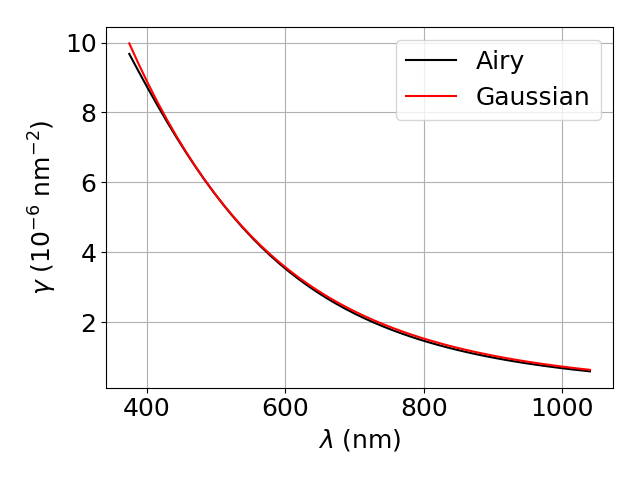

In [5]:

Res_Airy = Response_function(D0, delta_y, beam='Airy')
Res_Gaussian = Response_function(D0, delta_y, beam='Gaussian')


fig = plt.figure()

plt.plot(Lambda*1e9, Res_Airy*1e-12, color='black', label='Airy')
plt.plot(Lambda*1e9, Res_Gaussian*1e-12, color='red', label="Gaussian")
#plt.plot(Delta_y*1e9, -Res_DL*1e18, color='black', label='DL')

plt.xlabel('$\lambda$ (nm)')
plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')
plt.legend()
plt.grid()
plt.tight_layout()

# plt.savefig('Comparaison Airy et Gaussien en fct de Lambda.png')
# plt.savefig('Comparaison Airy et Gaussien en fct de Lambda.pdf')

## 2D visualisation of response function

In [6]:
LLambda, DDelta_y = np.meshgrid(Lambda, Delta_y)

R2F_2D = Response_function(D0, Delta_y, beam='Airy')

(50, 100)


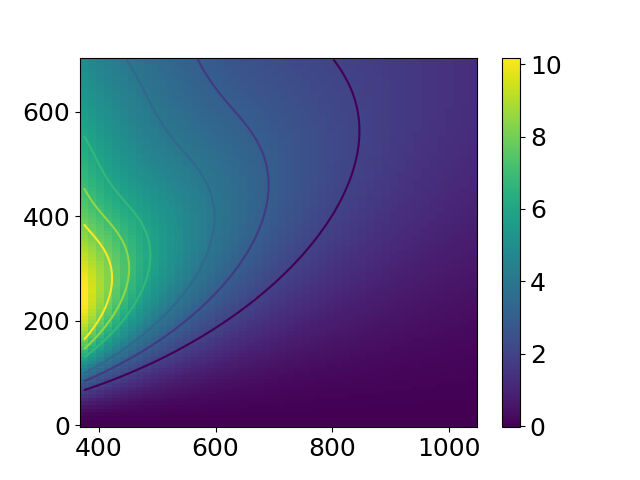

In [7]:
print(np.shape(R2F_2D))

fig, ax = plt.subplots()
plt.pcolormesh(Lambda*1e9, Delta_y*1e9, R2F_2D.transpose()*1e-12)

plt.colorbar()
plt.contour(LLambda*1e9, DDelta_y*1e9, R2F_2D.transpose()*1e-12, [2,3, 4, 5, 6, 7, 8])